# 03 Sentiment models: results and error analysis

How well three sentiment models agree with hand labels, and where they go wrong:

- **TF-IDF baseline** (`baseline`): logistic regression on character and word n-grams,
  trained on star labels (1–2 stars negative, 3 neutral, 4–5 positive).
- **CAMeLBERT-DA** (`camelbert`): pretrained Arabic sentiment model, Arabic reviews only.
- **XLM-RoBERTa** (`xlmr`): pretrained multilingual sentiment model, Arabic and English.

The pretrained models are used as they are, without training on these reviews.
All numbers are on the hand-labeled gold set (`data/labeled/gold.csv`): 400 Google Play
reviews, of which 389 are usable (11 were flagged as unclear or not about the app).
The sample is stratified by app, language and star group, so negative and 3-star reviews
are over-represented.

Run first:
```
python -m src.models.baseline
python -m src.models.transformer
python -m src.models.evaluate
```
All logic is in `src/models/`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display

from src.config import get_path
from src.models.error_analysis import error_table, length_group, predictions_for, star_vs_hand, wrong_for_all
from src.models.evaluate import gold_frame

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 120)

gold = gold_frame()
gold["length"] = length_group(gold["text"])
MODELS = ["baseline", "camelbert", "xlmr"]
print(len(gold), "usable gold reviews")
gold["sentiment"].value_counts()

389 usable gold reviews


sentiment
positive    230
negative    140
neutral      19
Name: count, dtype: int64

## 1. Results

Macro-F1 averages the F1 score of the three classes, so the rare neutral class counts as
much as the others. Intervals are 95% stratified bootstrap intervals. The weighted columns
reweight the sample to the real mix of reviews, and `binary_macro_f1` uses only reviews
labeled negative or positive.

In [2]:
results = pd.read_csv(get_path("results_gold"))
cols = ["model", "subset", "n", "macro_f1", "ci_low", "ci_high", "macro_f1_weighted",
        "binary_macro_f1", "f1_negative", "f1_neutral", "f1_positive"]
results[cols].round(2)

,model,subset,n,macro_f1,ci_low,ci_high,macro_f1_weighted,binary_macro_f1,f1_negative,f1_neutral,f1_positive
0,baseline,all,389,0.73,0.66,0.80,0.66,0.95,0.90,0.34,0.94
1,xlmr,all,389,0.77,0.71,0.83,0.81,0.96,0.89,0.45,0.97
2,baseline,arabic,196,0.70,0.60,0.78,0.64,0.93,0.88,0.29,0.92
3,camelbert,arabic,196,0.68,0.61,0.75,0.71,0.95,0.79,0.30,0.95
4,xlmr,arabic,196,0.74,0.66,0.81,0.82,0.94,0.85,0.41,0.95
5,baseline,english,193,0.77,0.63,0.88,0.76,0.97,0.93,0.43,0.96
6,xlmr,english,193,0.83,0.68,0.93,0.68,0.98,0.94,0.57,0.98


Differences between two models are tested on the same bootstrap resamples. Every interval
includes zero, so no model is clearly better than another on this sample.

In [3]:
pd.read_csv(get_path("results_gold_paired")).round(3)

,dataset,subset,metric,model_a,model_b,difference,ci_low,ci_high
0,gold,all,macro_f1,baseline,xlmr,-0.042,-0.124,0.046
1,gold,all,macro_f1_weighted,baseline,xlmr,-0.152,-0.256,0.057
2,gold,arabic,macro_f1,baseline,camelbert,0.018,-0.108,0.143
3,gold,arabic,macro_f1,baseline,xlmr,-0.042,-0.148,0.076
4,gold,arabic,macro_f1,camelbert,xlmr,-0.059,-0.136,0.023
5,gold,arabic,macro_f1_weighted,baseline,camelbert,-0.070,-0.202,0.142
6,gold,arabic,macro_f1_weighted,baseline,xlmr,-0.180,-0.293,0.051
7,gold,arabic,macro_f1_weighted,camelbert,xlmr,-0.111,-0.256,0.009
8,gold,english,macro_f1,baseline,xlmr,-0.058,-0.201,0.092
9,gold,english,macro_f1_weighted,baseline,xlmr,0.081,-0.172,0.209


How consistent are the hand labels themselves? 50 random reviews were labeled a second
time by the same person without seeing the first labels. This measures one labeler's
consistency, not agreement between different people, but it gives a rough ceiling for
what a model can reach against these labels.

In [4]:
pd.read_csv(get_path("gold_agreement")).round(3)

,label,n,agreement,kappa
0,sentiment,48,0.958,0.916
1,topic,48,0.917,0.839


## 2. Confusion matrices

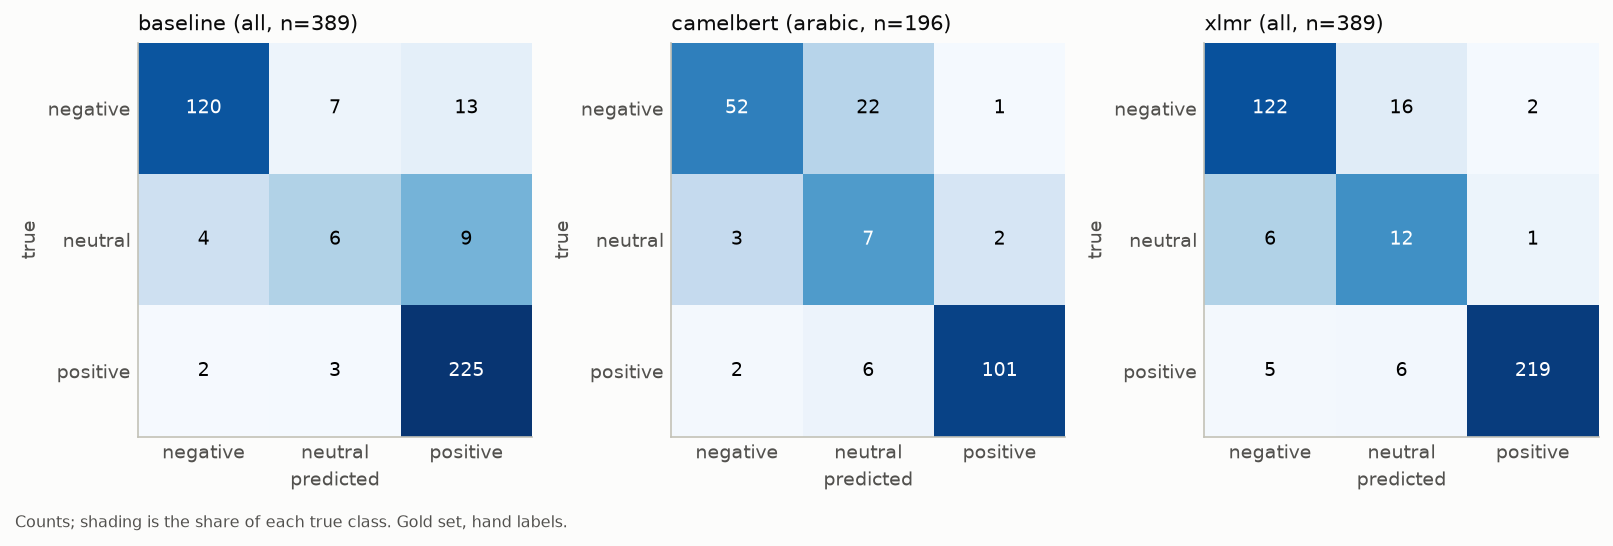

In [5]:
display(Image(filename=str(get_path("figures") / "sentiment_confusion_gold.png")))

The three models make different kinds of mistakes:

- The **pretrained models** most often call a negative review neutral. They were trained on
  other kinds of text (mainly tweets) and treat a complaint written as a plain statement
  of fact as neutral.
- The **baseline** almost never predicts neutral. Only about 2% of its star-labeled training
  reviews have 3 stars, so it puts most neutral reviews, and some negative ones, in the
  positive class.

## 3. Where the errors are

Each model makes only about 36–38 errors, so the groups below are small. Counts are shown
next to rates.

In [6]:
by_class = error_table(gold, "sentiment")
by_class.pivot(index="sentiment", columns="model", values=["errors", "n"])

errors                       n               
model     baseline camelbert xlmr baseline camelbert xlmr
sentiment                                                
negative        20        23   18      140        75  140
neutral         13         5    7       19        12   19
positive         5         8   11      230       109  230

In [7]:
error_table(gold, "lang").pivot(index="lang", columns="model", values=["errors", "n"])

errors                        n                 
model   baseline camelbert  xlmr baseline camelbert   xlmr
lang                                                      
arabic      25.0      36.0  27.0    196.0     196.0  196.0
english     13.0       NaN   9.0    193.0       NaN  193.0

In [8]:
error_table(gold, "length").pivot(index="length", columns="model", values=["errors", "n"])

errors                       n               
model  baseline camelbert xlmr baseline camelbert xlmr
length                                                
1-3           9         7    8      191        90  191
4-10         16        16   14       80        46   80
11-30        11        10    8       81        46   81
31+           2         3    6       37        14   37

- **Arabic is harder than English** for both models that score both languages
  (baseline 25 errors on 196 Arabic reviews vs. 13 on 193 English; XLM-RoBERTa 27 vs. 9).
- **Very short reviews are easy.** Reviews of 1–3 words are mostly "ممتاز", "good" and
  similar, and every model gets more than 90% of them right. Reviews of 4–10 words have
  the highest error rate: long enough to describe a problem, too short to give much context.

## 4. Star labels vs. hand labels

The baseline is trained on star ratings. Where a review's text and its stars disagree,
does the model follow the text or the stars?

In [9]:
pd.crosstab(gold["star_sentiment"], gold["sentiment"], rownames=["star group"], colnames=["hand label"])

hand label,negative,neutral,positive
star group,,,
negative,114,6,35
neutral,25,10,64
positive,1,3,131


In [10]:
star_vs_hand(gold)

,model,n,matches_hand,matches_star,matches_neither
0,baseline,134,116,12,6
1,camelbert,67,52,12,3
2,xlmr,134,114,17,3


In 134 of the 389 reviews the hand label differs from the star group. Most of these are
3-star reviews whose text is clearly positive or negative, and 35 are 1–2 star reviews whose
text is positive (often just "good" or "ممتاز"). All three models usually follow the text:
the baseline agrees with the hand label on 116 of the 134 and with the star group on 12. It
labels 34 of the 35 positive-text 1–2 star reviews as positive. Training on noisy star labels
did not teach the baseline to repeat those labels: a word like "ممتاز" appears overwhelmingly
in 4–5 star reviews, so the few 1-star reviews that contain it have little effect.

## 5. Neutral reviews

Only 19 reviews are neutral by hand. Most are requests or suggestions ("please include
stc pay as one payment option"), short lukewarm verdicts ("يعني متوسط", "Ok") or reviews
that weigh good and bad equally.

In [11]:
predictions_for(gold, "neutral")

,negative,neutral,positive
model,,,
baseline,4,6,9
camelbert,3,7,2
xlmr,6,12,1


In [12]:
gold.loc[gold["sentiment"] == "neutral", ["lang", "rating", "baseline_pred", "camelbert_pred", "xlmr_pred", "text"]]

,lang,rating,baseline_pred,camelbert_pred,xlmr_pred,text
0,arabic,1,positive,negative,neutral,مرظي
4,arabic,5,positive,neutral,neutral,لو تقدرو تعطونا كاش ياريت وتقسطون على اربع دفعات
8,arabic,5,positive,positive,neutral,تمام
11,english,3,positive,NaN,neutral,please include stc pay as one payment option.
26,english,1,negative,NaN,negative,Only Dubai and Saudi Arabia. Doesn't work in Europe
72,arabic,3,positive,neutral,neutral,يعني متوسط
127,arabic,3,negative,neutral,positive,اتمنى تعديل طريقة السداد بحيث تمكنني من السداد لاكثر من منتج خلال مرحلة سداد واحد بمعنى وضع ايقونه امام الدفاعات ويت...
130,arabic,3,neutral,neutral,neutral,تحويل الدفعات لأكثر من ٣ دفعات
162,english,3,neutral,NaN,neutral,easy to use but limit should be 5000 minimum
169,english,3,positive,NaN,neutral,Ok


XLM-RoBERTa gets 12 of the 19 right, the baseline 6, and CAMeLBERT 7 of the 12 Arabic ones.
With so few neutral reviews, one review more or less changes neutral F1 by several points,
which is why the macro-F1 intervals are wide.

## 6. Error types, with examples

All 73 reviews that at least one model gets wrong were read and grouped by what seems to
cause the error. This is a qualitative reading, not a second labeling. No review among the
errors reads as sarcasm.

In [13]:
COLS = ["gold_id", "lang", "rating", "sentiment", "baseline_pred", "camelbert_pred", "xlmr_pred", "text"]


def show(ids: list[str]) -> pd.DataFrame:
    """Show selected gold reviews with each model's prediction."""
    return gold.set_index("gold_id").loc[ids].reset_index()[COLS]

**Reported problems read as neutral.** Labeling rule: a review that reports a problem is
negative even when it is written calmly. The pretrained models often disagree: this is
the most common error for CAMeLBERT (22 of its 36 errors) and XLM-RoBERTa (16 of 36).
Some of these reviews even contain a clearly negative word ("سئ", bad).

In [14]:
show(["d03bc07cb374", "cc79da890529", "186b73f66a7f", "3f6a24abd929", "2a3a055c123e"])

,gold_id,lang,rating,sentiment,baseline_pred,camelbert_pred,xlmr_pred,text
0,d03bc07cb374,arabic,3,negative,negative,neutral,neutral,ليس لديهم تواصل عن طريق الواتساب
1,cc79da890529,arabic,3,negative,negative,neutral,neutral,شركة تمارا تاخذ رسوم في بعض المواقع وهذا لايوجد بالشركات الأخرى
2,186b73f66a7f,arabic,2,negative,negative,neutral,neutral,لمن اشتري شي اخر يطلب مني سداد قسط من القديم علما انه متبقي عن القسط اكثر من ٢٠ يوم
3,3f6a24abd929,arabic,1,negative,negative,neutral,negative,سئ. يرفض دخول رقم الجوال
4,2a3a055c123e,arabic,1,negative,negative,neutral,negative,بعد التحديث الاخير التطبيق ما يفتح وعندي سداد ولازم ادفع


**Requests and suggestions.** Polite requests carry positive words ("please", "ياريت",
"شكرا"), and the baseline calls most of them positive. A question such as "why isn't Oman
added?" goes the other way and reads as a complaint to two of the models. Requests are
neutral by hand unless they complain about something.

In [15]:
show(["44de9ce4e2fa", "a078a1ed5719", "64c666acf9aa", "7c5bc4bb8938"])

,gold_id,lang,rating,sentiment,baseline_pred,camelbert_pred,xlmr_pred,text
0,44de9ce4e2fa,english,3,neutral,positive,NaN,neutral,please include stc pay as one payment option.
1,a078a1ed5719,arabic,5,neutral,positive,neutral,neutral,لو تقدرو تعطونا كاش ياريت وتقسطون على اربع دفعات
2,64c666acf9aa,arabic,4,neutral,positive,neutral,neutral,اتمنى يوجد تأجيل دفع اسبوع فأكثر زي تابي وشكرا
3,7c5bc4bb8938,arabic,3,neutral,negative,neutral,negative,لماذا لا يم إضافة سلطنة عمان


**Mixed reviews.** Praise followed by a complaint ("جيد بس ...", "good but ..."). The hand
label depends on which part weighs more, and the models split.

In [16]:
show(["1965d4ccd436", "a0fff6162616", "c54cc17e0039", "28f7ed5cab28"])

,gold_id,lang,rating,sentiment,baseline_pred,camelbert_pred,xlmr_pred,text
0,1965d4ccd436,arabic,1,neutral,neutral,positive,negative,جميل بس المشكل رسوم زيادة مره
1,a0fff6162616,arabic,3,positive,neutral,neutral,neutral,جيد بس مافيه تحديد الأقساط
2,c54cc17e0039,english,3,positive,neutral,NaN,negative,"the app is very good The app is great for local stores, but I'm disappointed it doesn't work on global sites like eB..."
3,28f7ed5cab28,english,2,neutral,neutral,NaN,negative,Good service but sometimes it's not good


**Dialect, misspelling and idiom.** "ماجازلي البرنامج" (Gulf dialect: "I didn't like the app"),
"تفك زنقة الواحد" ("gets you out of a tight spot", positive), "مرظي" (a misspelling of
"مرضي", satisfactory), "help full" and "hassle free", where the word "hassle" pulls
XLM-RoBERTa towards negative.

In [17]:
show(["7c6170ac4260", "b59f228e0282", "9a1e949dee8e", "ba494b79a471", "c59a8118b310"])

,gold_id,lang,rating,sentiment,baseline_pred,camelbert_pred,xlmr_pred,text
0,7c6170ac4260,arabic,1,negative,positive,negative,negative,ماجازلي البرنامج
1,b59f228e0282,arabic,5,positive,positive,negative,negative,بصراحة تفك زنقة الواحد
2,9a1e949dee8e,arabic,1,neutral,positive,negative,neutral,مرظي
3,ba494b79a471,english,5,positive,positive,NaN,negative,help full
4,c59a8118b310,english,4,positive,positive,NaN,negative,hassle free process


**Words that point the wrong way.** A thank-you for dropping late fees mentions
"رسوم التأخير" (late fees), which is a strong negative signal in the training data.

In [18]:
show(["7734eaf3f60f"])

,gold_id,lang,rating,sentiment,baseline_pred,camelbert_pred,xlmr_pred,text
0,7734eaf3f60f,arabic,1,positive,negative,neutral,neutral,تم تعديل سياسه الشركه بعدم اخذ رسوم التأخير ، شكرا


## 7. Reviews every model gets wrong

In [19]:
wrong_for_all(gold)[COLS[1:]]

,lang,rating,sentiment,baseline_pred,camelbert_pred,xlmr_pred,text
2,arabic,1,negative,positive,neutral,neutral,ما تظهر طريقه الدفع في مواقع ثانيه
26,english,1,neutral,negative,NaN,negative,Only Dubai and Saudi Arabia. Doesn't work in Europe
79,arabic,1,negative,positive,neutral,neutral,لايوجد تذكير
84,arabic,3,negative,neutral,positive,neutral,المفروض من تاني يوم تأخير تزودو ١٥ ريال
106,english,3,negative,positive,NaN,neutral,"The first installment is taken in excess, one-fourth is not taken."
194,arabic,2,neutral,negative,negative,negative,تمارا ممتازه لكن للأسف المتاجر والشركات لإحتالية الوهمية وسيئة السمعة تبقى تمارا نافذة دفع مغرية لها نرجو تحقق من ال...
240,arabic,3,negative,positive,neutral,neutral,تعليق دفع الدفعهاو ايضافة بطاقة بنكيه
273,english,3,positive,neutral,NaN,negative,"the app is very good The app is great for local stores, but I'm disappointed it doesn't work on global sites like eB..."
277,arabic,1,positive,negative,neutral,neutral,تم تعديل سياسه الشركه بعدم اخذ رسوم التأخير ، شكرا
286,english,3,negative,positive,NaN,neutral,mobile price high


12 reviews are misclassified by every model that scores them. Most are short, calm
complaints ("لايوجد تذكير", no reminder; "mobile price high") or mixed reviews where the
hand label depends on a judgment about which part matters more.

## Summary

- On 389 hand-labeled reviews, the TF-IDF baseline (macro-F1 0.73) and XLM-RoBERTa (0.77)
  are not significantly different; on Arabic reviews, neither is CAMeLBERT (0.68).
- All models separate negative from positive reviews well (two-class macro-F1 0.93–0.98).
  The three-class scores are held down by the neutral class, which has only 19 reviews.
- The models fail in different ways. The pretrained models read calm complaints as neutral.
  The baseline rarely predicts neutral and reads polite requests as positive.
- Noisy star labels did not make the baseline repeat the stars: on reviews where the text
  and the stars disagree, it follows the text in 116 of 134 cases.
- Errors are more frequent in Arabic reviews and in reviews of 4–10 words. Dialect,
  misspellings and mixed praise-and-complaint reviews are typical hard cases.